<a href="https://colab.research.google.com/github/Madss28/Madss28/blob/main/UK_NHS_Waiting_Times_and_Performance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")



In [18]:
import pandas as pd

# Direct loading of the selected file
file_path = "/content/September-2026-CSV-Re72Eh.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,Period,Org Code,Parent Org,Org name,A&E attendances Type 1,A&E attendances Type 2,A&E attendances Other A&E Department,A&E attendances Booked Appointments Type 1,A&E attendances Booked Appointments Type 2,A&E attendances Booked Appointments Other Department,...,Attendances over 4hrs Other Department,Attendances over 4hrs Booked Appointments Type 1,Attendances over 4hrs Booked Appointments Type 2,Attendances over 4hrs Booked Appointments Other Department,Patients who have waited 4-12 hs from DTA to admission,Patients who have waited 12+ hrs from DTA to admission,Emergency admissions via A&E - Type 1,Emergency admissions via A&E - Type 2,Emergency admissions via A&E - Other A&E department,Other emergency admissions
0,MSitAE-SEPTEMBER-2026,AJN,NHS ENGLAND NORTH EAST AND YORKSHIRE,WORKINGTON HEALTH LIMITED,0,0,492,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,MSitAE-SEPTEMBER-2026,NTV0B,NHS ENGLAND SOUTH EAST,ASHFORD WALK-IN-CENTRE,0,0,2584,0,0,0,...,273,0,0,0,0,0,0,0,0,0
2,MSitAE-SEPTEMBER-2026,NTV0W,NHS ENGLAND SOUTH EAST,WOKING WALK IN CENTRE,0,0,2773,0,0,0,...,84,0,0,0,0,0,0,0,0,0
3,MSitAE-SEPTEMBER-2026,RYY,NHS ENGLAND SOUTH EAST,KENT COMMUNITY HEALTH NHS FOUNDATION TRUST,0,0,6655,0,0,0,...,95,0,0,0,0,0,0,0,0,0
4,MSitAE-SEPTEMBER-2026,AAH,NHS ENGLAND SOUTH WEST,TETBURY HOSPITAL TRUST LTD,0,0,702,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [19]:
# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print(df.columns.tolist())

# Data types and non-null counts
df.info()

Dataset shape: (192, 22)
['Period', 'Org Code', 'Parent Org', 'Org name', 'A&E attendances Type 1', 'A&E attendances Type 2', 'A&E attendances Other A&E Department', 'A&E attendances Booked Appointments Type 1', 'A&E attendances Booked Appointments Type 2', 'A&E attendances Booked Appointments Other Department', 'Attendances over 4hrs Type 1', 'Attendances over 4hrs Type 2', 'Attendances over 4hrs Other Department', 'Attendances over 4hrs Booked Appointments Type 1', 'Attendances over 4hrs Booked Appointments Type 2', 'Attendances over 4hrs Booked Appointments Other Department', 'Patients who have waited 4-12 hs from DTA to admission', 'Patients who have waited 12+ hrs from DTA to admission', 'Emergency admissions via A&E - Type 1', 'Emergency admissions via A&E - Type 2', 'Emergency admissions via A&E - Other A&E department', 'Other emergency admissions']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 192 entries, 0 to 191
Data columns (total 22 columns):
 #   Column               

In [20]:
# Missing values
print("Missing values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Summary statistics
df.describe()

Missing values:
Period                                                        0
Org Code                                                      0
Parent Org                                                    0
Org name                                                      0
A&E attendances Type 1                                        0
A&E attendances Type 2                                        0
A&E attendances Other A&E Department                          0
A&E attendances Booked Appointments Type 1                    0
A&E attendances Booked Appointments Type 2                    0
A&E attendances Booked Appointments Other Department          0
Attendances over 4hrs Type 1                                  0
Attendances over 4hrs Type 2                                  0
Attendances over 4hrs Other Department                        0
Attendances over 4hrs Booked Appointments Type 1              0
Attendances over 4hrs Booked Appointments Type 2              0
Attendances over 4hrs Bo

,A&E attendances Type 1,A&E attendances Type 2,A&E attendances Other A&E Department,A&E attendances Booked Appointments Type 1,A&E attendances Booked Appointments Type 2,A&E attendances Booked Appointments Other Department,Attendances over 4hrs Type 1,Attendances over 4hrs Type 2,Attendances over 4hrs Other Department,Attendances over 4hrs Booked Appointments Type 1,Attendances over 4hrs Booked Appointments Type 2,Attendances over 4hrs Booked Appointments Other Department,Patients who have waited 4-12 hs from DTA to admission,Patients who have waited 12+ hrs from DTA to admission,Emergency admissions via A&E - Type 1,Emergency admissions via A&E - Type 2,Emergency admissions via A&E - Other A&E department,Other emergency admissions
count,1.920000e+02,192.000000,192.000000,192.000000,192.000000,192.000000,192.000000,192.000000,192.000000,192.000000,192.000000,192.000000,192.000000,192.000000,192.000000,192.000000,192.000000,192.000000
mean,1.536917e+04,573.062500,8743.093750,288.635417,5.197917,486.916667,6089.895833,31.864583,317.395833,82.833333,0.614583,6.052083,818.927083,526.895833,4111.197917,15.979167,53.197917,1404.604167
std,1.061954e+05,4033.847666,60403.813619,2032.225572,49.202886,3435.060049,42084.927402,228.073889,2202.980603,588.289733,6.005878,43.168941,5665.234591,3651.495433,28416.673768,128.877431,384.982630,9740.399115
min,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000e+00,0.000000,1074.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,7.826500e+03,0.000000,3196.000000,0.000000,0.000000,0.000000,2846.500000,0.000000,46.500000,0.000000,0.000000,0.000000,345.000000,48.000000,1808.500000,0.000000,0.000000,316.500000
75%,1.231700e+04,0.000000,6754.500000,7.500000,0.000000,114.250000,5080.500000,0.000000,236.500000,0.000000,0.000000,0.000000,648.750000,489.250000,3427.000000,0.000000,0.000000,917.750000
max,1.475440e+06,55014.000000,839337.000000,27709.000000,499.000000,46744.000000,584630.000000,3059.000000,30470.000000,7952.000000,59.000000,581.000000,78617.000000,50582.000000,394675.000000,1534.000000,5107.000000,134842.000000


In [21]:
df_clean = df[df["Org Code"] != "TOTAL"].copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

df_clean.head()

Original dataset: (192, 22)
Cleaned dataset: (191, 22)


,Period,Org Code,Parent Org,Org name,A&E attendances Type 1,A&E attendances Type 2,A&E attendances Other A&E Department,A&E attendances Booked Appointments Type 1,A&E attendances Booked Appointments Type 2,A&E attendances Booked Appointments Other Department,...,Attendances over 4hrs Other Department,Attendances over 4hrs Booked Appointments Type 1,Attendances over 4hrs Booked Appointments Type 2,Attendances over 4hrs Booked Appointments Other Department,Patients who have waited 4-12 hs from DTA to admission,Patients who have waited 12+ hrs from DTA to admission,Emergency admissions via A&E - Type 1,Emergency admissions via A&E - Type 2,Emergency admissions via A&E - Other A&E department,Other emergency admissions
0,MSitAE-SEPTEMBER-2026,AJN,NHS ENGLAND NORTH EAST AND YORKSHIRE,WORKINGTON HEALTH LIMITED,0,0,492,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,MSitAE-SEPTEMBER-2026,NTV0B,NHS ENGLAND SOUTH EAST,ASHFORD WALK-IN-CENTRE,0,0,2584,0,0,0,...,273,0,0,0,0,0,0,0,0,0
2,MSitAE-SEPTEMBER-2026,NTV0W,NHS ENGLAND SOUTH EAST,WOKING WALK IN CENTRE,0,0,2773,0,0,0,...,84,0,0,0,0,0,0,0,0,0
3,MSitAE-SEPTEMBER-2026,RYY,NHS ENGLAND SOUTH EAST,KENT COMMUNITY HEALTH NHS FOUNDATION TRUST,0,0,6655,0,0,0,...,95,0,0,0,0,0,0,0,0,0
4,MSitAE-SEPTEMBER-2026,AAH,NHS ENGLAND SOUTH WEST,TETBURY HOSPITAL TRUST LTD,0,0,702,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [22]:
attendance_cols = [
    "A&E attendances Type 1",
    "A&E attendances Type 2",
    "A&E attendances Other A&E Department",
    "A&E attendances Booked Appointments Type 1",
    "A&E attendances Booked Appointments Type 2",
    "A&E attendances Booked Appointments Other Department"
]

df_clean["Total_Attendances"] = df_clean[
    attendance_cols
].sum(axis=1)

df_clean[
    ["Org name", "Total_Attendances"]
].head(10)

,Org name,Total_Attendances
0,WORKINGTON HEALTH LIMITED,492
1,ASHFORD WALK-IN-CENTRE,2584
2,WOKING WALK IN CENTRE,2773
3,KENT COMMUNITY HEALTH NHS FOUNDATION TRUST,6655
4,TETBURY HOSPITAL TRUST LTD,702
5,BECKENHAM BEACON UCC,3736
6,FAVERSHAM MEDICAL PRACTICE MIU,2784
7,PHL LYMINGTON UTC,3185
8,LATHAM HOUSE MEDICAL PRACTICE,384
9,FIRST COMMUNITY HEALTH AND CARE CIC,2453


In [23]:
waiting_cols = [
    "Attendances over 4hrs Type 1",
    "Attendances over 4hrs Type 2",
    "Attendances over 4hrs Other Department",
    "Attendances over 4hrs Booked Appointments Type 1",
    "Attendances over 4hrs Booked Appointments Type 2",
    "Attendances over 4hrs Booked Appointments Other Department"
]

df_clean["Over_4_Hours"] = df_clean[
    waiting_cols
].sum(axis=1)

df_clean["Within_4_Hours_Pct"] = np.where(
    df_clean["Total_Attendances"] > 0,
    (
        (df_clean["Total_Attendances"] - df_clean["Over_4_Hours"])
        / df_clean["Total_Attendances"]
    ) * 100,
    np.nan
)

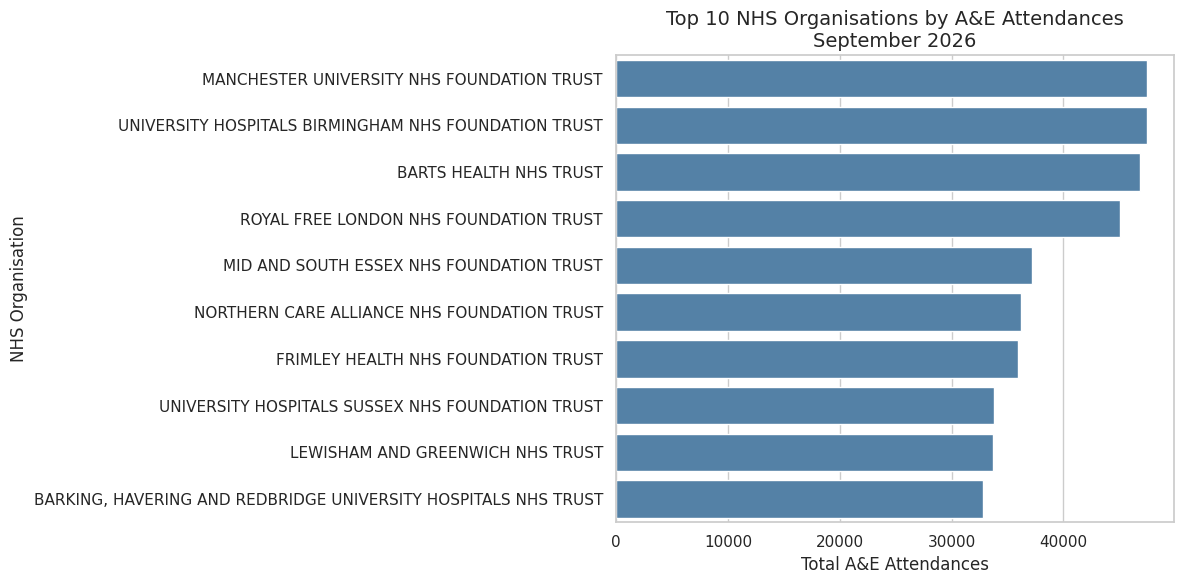

In [24]:
top10 = df_clean.nlargest(
    10, "Total_Attendances"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top10,
    x="Total_Attendances",
    y="Org name",
    color="steelblue"
)

plt.title(
    "Top 10 NHS Organisations by A&E Attendances\nSeptember 2026",
    fontsize=14
)

plt.xlabel("Total A&E Attendances")
plt.ylabel("NHS Organisation")

plt.tight_layout()
plt.show()

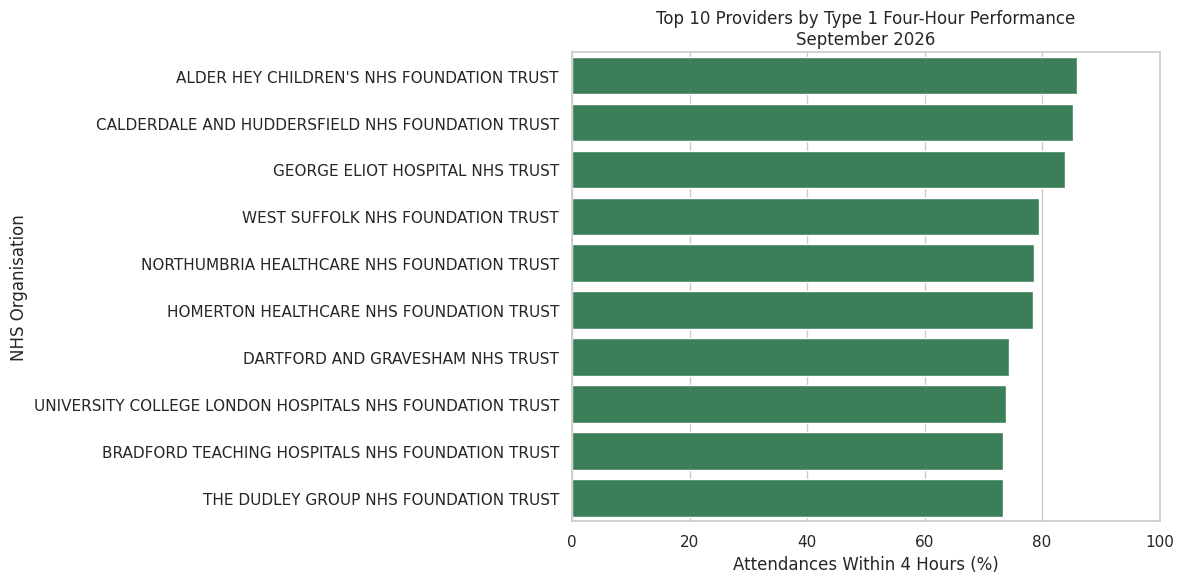

In [25]:
type1 = df_clean[
    df_clean["A&E attendances Type 1"] >= 5000
].copy()

type1["Type1_Within_4hrs_Pct"] = (
    1 - (
        type1["Attendances over 4hrs Type 1"]
        / type1["A&E attendances Type 1"]
    )
) * 100

top_performance = type1.nlargest(
    10, "Type1_Within_4hrs_Pct"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_performance,
    x="Type1_Within_4hrs_Pct",
    y="Org name",
    color="seagreen"
)

plt.title(
    "Top 10 Providers by Type 1 Four-Hour Performance\nSeptember 2026"
)

plt.xlabel("Attendances Within 4 Hours (%)")
plt.ylabel("NHS Organisation")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

In [26]:
df_clean.to_csv(
    "NHS_September_2026_Cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [27]:
# Group NHS organisations by region
regional = df_clean.groupby("Parent Org").agg(
    Total_Attendances=("Total_Attendances", "sum"),
    Over_4_Hours=("Over_4_Hours", "sum")
).reset_index()

# Calculate regional four-hour performance
regional["Within_4_Hours_Pct"] = (
    (regional["Total_Attendances"] - regional["Over_4_Hours"])
    / regional["Total_Attendances"]
) * 100

regional = regional.sort_values(
    "Within_4_Hours_Pct", ascending=False
)

display(regional)

,Parent Org,Total_Attendances,Over_4_Hours,Within_4_Hours_Pct
1,NHS ENGLAND LONDON,432712,99481,77.009882
5,NHS ENGLAND SOUTH EAST,376448,89427,76.244528
3,NHS ENGLAND NORTH EAST AND YORKSHIRE,379212,94096,75.186439
0,NHS ENGLAND EAST OF ENGLAND,249177,64676,74.044153
2,NHS ENGLAND MIDLANDS,448136,121483,72.891488
4,NHS ENGLAND NORTH WEST,340301,95887,71.822886
6,NHS ENGLAND SOUTH WEST,218757,61701,71.794731


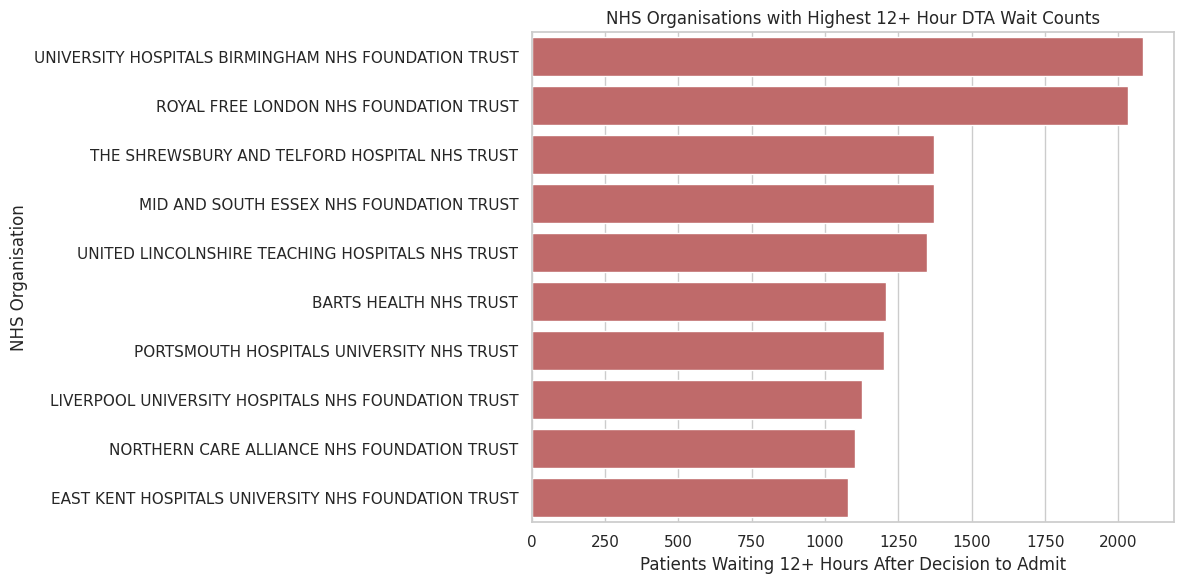

In [28]:
# Calculate emergency admissions through A&E
admission_cols = [
    "Emergency admissions via A&E - Type 1",
    "Emergency admissions via A&E - Type 2",
    "Emergency admissions via A&E - Other A&E department"
]

df_clean["AE_Emergency_Admissions"] = (
    df_clean[admission_cols].sum(axis=1)
)

# Calculate 12+ hour DTA waits
df_clean["DTA_12hr_Waits"] = df_clean[
    "Patients who have waited 12+ hrs from DTA to admission"
]

# Identify organisations with highest numbers of long waits
top_delays = df_clean.nlargest(
    10, "DTA_12hr_Waits"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_delays,
    x="DTA_12hr_Waits",
    y="Org name",
    color="indianred"
)

plt.title("NHS Organisations with Highest 12+ Hour DTA Wait Counts")
plt.xlabel("Patients Waiting 12+ Hours After Decision to Admit")
plt.ylabel("NHS Organisation")

plt.tight_layout()
plt.show()

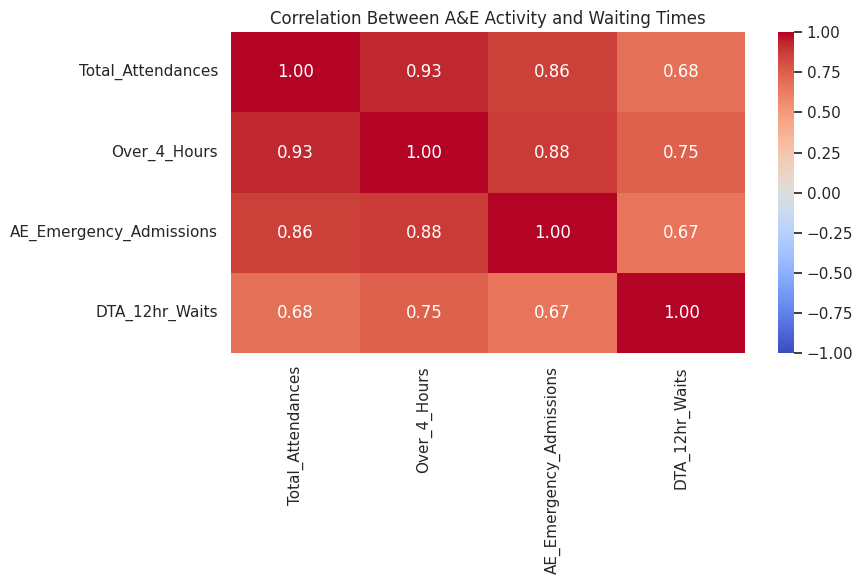

In [29]:
# Select variables
correlation_data = df_clean[
    [
        "Total_Attendances",
        "Over_4_Hours",
        "AE_Emergency_Admissions",
        "DTA_12hr_Waits"
    ]
]

# Calculate correlation matrix
corr_matrix = correlation_data.corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between A&E Activity and Waiting Times")
plt.tight_layout()
plt.show()

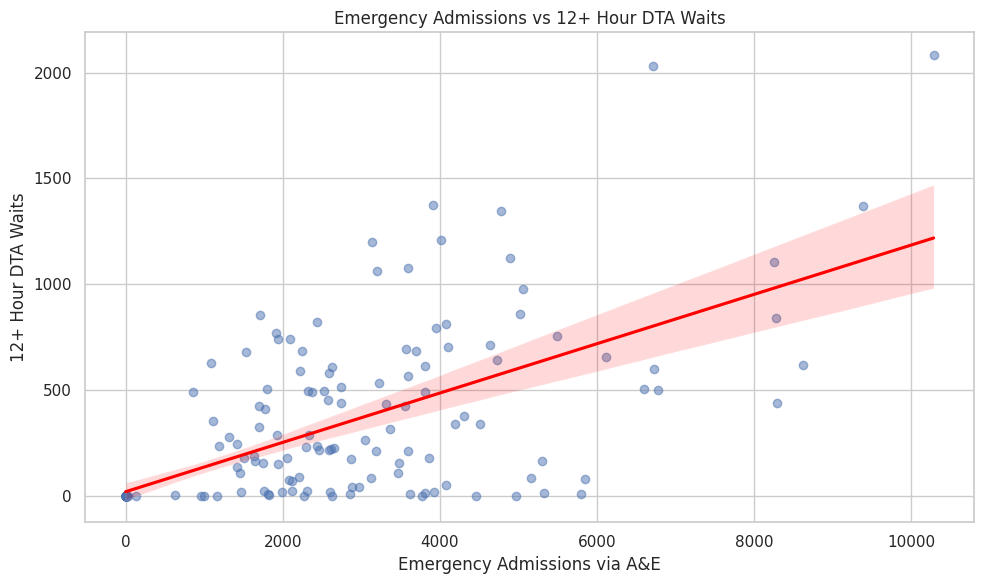

In [30]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x="AE_Emergency_Admissions",
    y="DTA_12hr_Waits",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Emergency Admissions vs 12+ Hour DTA Waits")
plt.xlabel("Emergency Admissions via A&E")
plt.ylabel("12+ Hour DTA Waits")

plt.tight_layout()
plt.show()

In [31]:
import os

os.makedirs("outputs", exist_ok=True)

# Save regional performance data
regional.to_csv(
    "outputs/regional_performance.csv",
    index=False
)

# Save the expanded cleaned dataset
df_clean.to_csv(
    "outputs/nhs_september_2026_analysis.csv",
    index=False
)

# Save the correlation matrix
corr_matrix.to_csv(
    "outputs/correlation_matrix.csv"
)

Results and Discussion

This project analysed NHS England A&E performance data for September 2026, focusing on attendance volumes, four-hour waiting times, emergency admissions and regional differences.

The analysis identified variations in A&E performance across NHS organisations and regions. London recorded the highest overall four-hour performance (77.0%), while the South West recorded the lowest (71.8%). These differences may reflect variations in service demand, capacity and operational pressures, although further investigation would be needed to establish the underlying causes.

Correlation analysis showed a strong positive relationship between total A&E attendances and the number of patients waiting over four hours (r = 0.93). Emergency admission volumes were also positively associated with 12-hour admission delays (r = 0.67). These findings suggest that higher patient volumes are associated with greater numbers of delayed attendances and admissions, but do not establish a causal relationship.

Overall, the project demonstrates how Python-based data analysis and visualisation can be used to explore healthcare performance and identify patterns in publicly available NHS data. As the analysis covers a single month, further work using historical data would help assess longer-term trends and seasonal variations.

Key Skills Demonstrated

Python · Pandas · NumPy · Data Cleaning · Exploratory Data Analysis · Statistical Analysis · Correlation Analysis · Matplotlib · Seaborn · Data Visualisation